<a href="https://colab.research.google.com/github/Fathina-codes/FDS_Record/blob/main/Ex_6_7_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

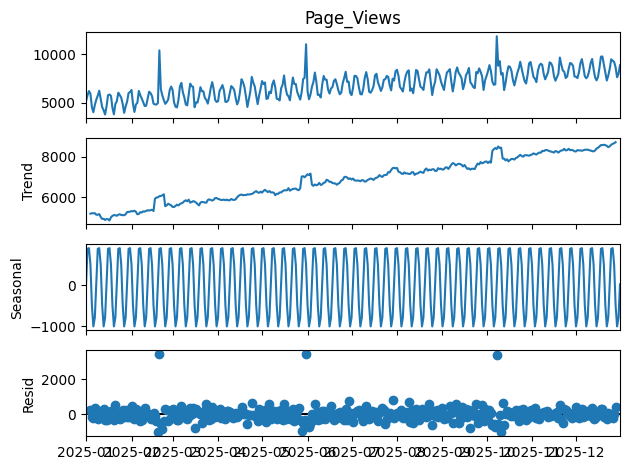

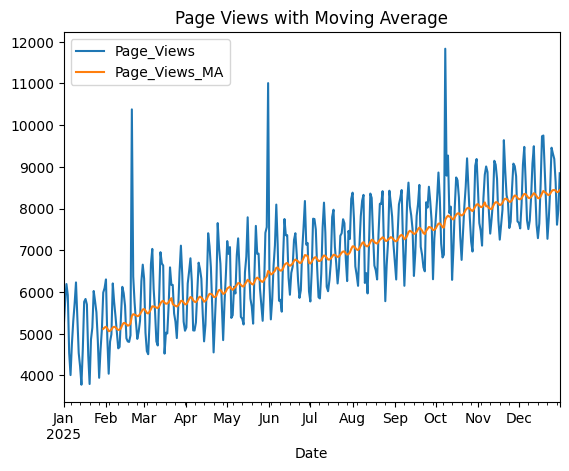

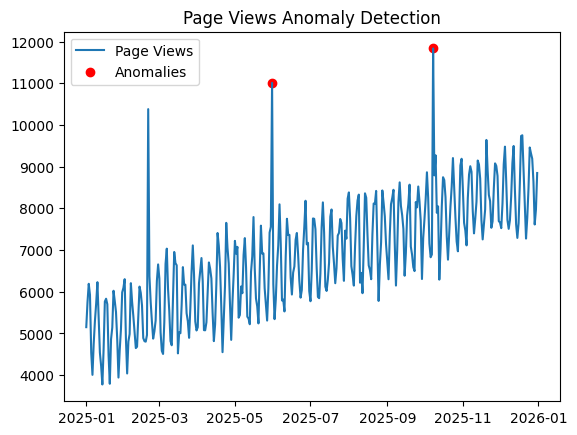

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Load data from CSV
data = pd.read_csv('/content/website_traffic (1).csv', parse_dates=['Date'], index_col='Date')

# 2. Seasonal Decomposition
decomposition = seasonal_decompose(data['Page_Views'], model='additive')
decomposition.plot()
plt.show()

# 3. 30-Day Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

# 4. Anomaly Detection via Z-Score (Fixed syntax error)
data['Page_Views_Z'] = (
    data['Page_Views'] - data['Page_Views'].mean()
) / data['Page_Views'].std()

anomalies = data[data['Page_Views_Z'].abs() > 3]

plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(
    anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies'
)
plt.legend()
plt.title('Page Views Anomaly Detection')
plt.show()

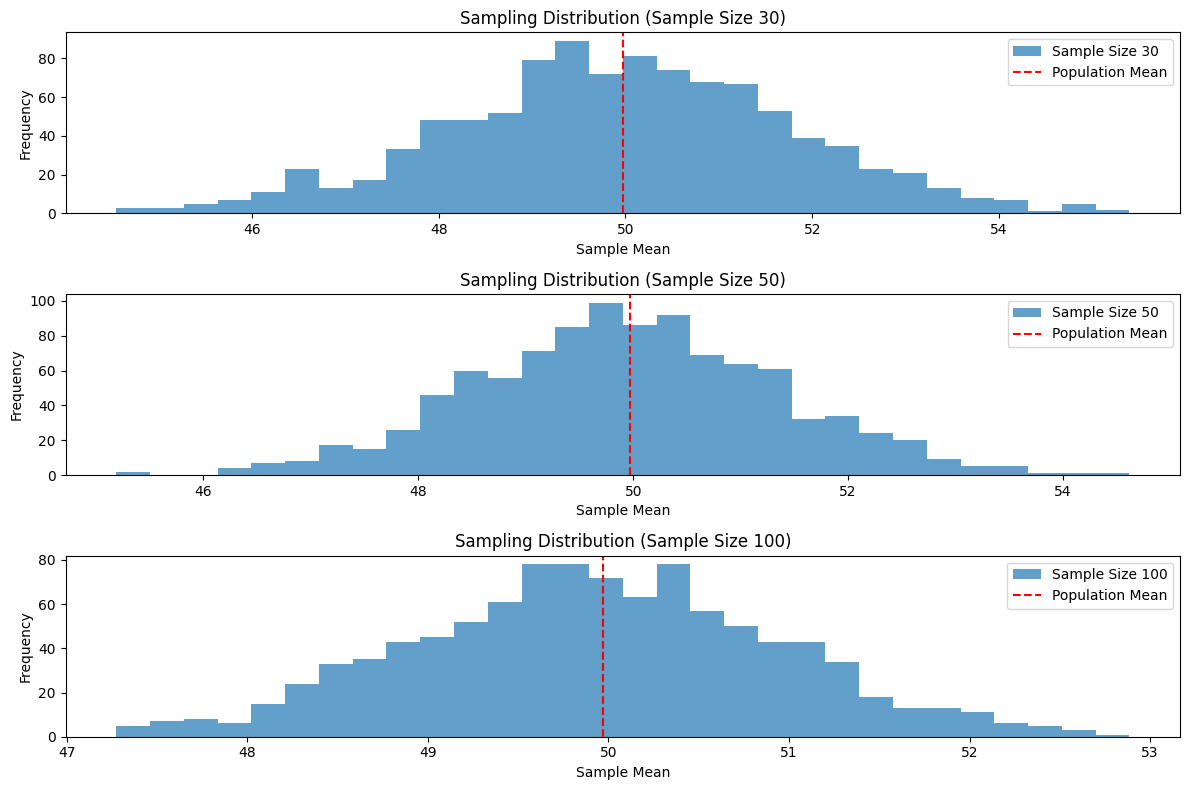

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Generate a population (e.g., normal distribution)
population_mean = 50
population_std = 10
population_size = 100000
population = np.random.normal(population_mean, population_std, population_size)

# Step 2: Random sampling
sample_sizes = [30, 50, 100]  # different sample sizes to consider
num_samples = 1000  # number of samples for each sample size

sample_means = {}

for size in sample_sizes:
    sample_means[size] = []
    for _ in range(num_samples):
        sample = np.random.choice(population, size=size, replace=False)
        sample_means[size].append(np.mean(sample))

# Step 3: Plotting sampling distributions
plt.figure(figsize=(12, 8))

for i, size in enumerate(sample_sizes):
    plt.subplot(len(sample_sizes), 1, i + 1)
    plt.hist(
        sample_means[size], bins=30, alpha=0.7, label=f'Sample Size {size}'
    )
    plt.axvline(
        np.mean(population),
        color='red',
        linestyle='dashed',
        linewidth=1.5,
        label='Population Mean',
    )
    plt.title(f'Sampling Distribution (Sample Size {size})')
    plt.xlabel('Sample Mean')
    plt.ylabel('Frequency')
    plt.legend()

plt.tight_layout()
plt.show()

In [4]:
import numpy as np
import scipy.stats as stats

# Define the sample data (hypothetical weights in grams)
sample_data = np.array([
    152, 148, 151, 149, 147, 153, 150, 148, 152, 149,
    151, 150, 149, 152, 151, 148, 150, 152, 149, 150,
    148, 153, 151, 150, 149, 152, 148, 151, 150, 153
])

# Population mean under the null hypothesis
population_mean = 150

# Calculate sample statistics
sample_mean = np.mean(sample_data)
sample_std = np.std(sample_data, ddof=1)  # Sample standard deviation

# Number of observations
n = len(sample_data)

# Calculate the Z-statistic
z_statistic = (sample_mean - population_mean) / (sample_std / np.sqrt(n))

# Calculate the p-value (Two-tailed test)
p_value = 2 * (1 - stats.norm.cdf(np.abs(z_statistic)))

# Print results
print(f"Sample Mean: {sample_mean:.2f}")
print(f"Z-Statistic: {z_statistic:.4f}")
print(f"P-Value: {p_value:.4f}")

# Decision based on the significance level
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The average weight is significantly different from 150 grams.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference in average weight from 150 grams.")

Sample Mean: 150.20
Z-Statistic: 0.6406
P-Value: 0.5218
Fail to reject the null hypothesis: There is no significant difference in average weight from 150 grams.
